# a/b-тестирование рекламной кампании

## 1. бизнес-задача
Оценить, увеличивает ли показ рекламного объявления конверсию пользователей в покупку по сравнению с показом контрольного информационного сообщения (PSA)
## 2. цель исследования
Сравнить конверсии тестовой (`ad`) и контрольной (`psa`) групп, оценить величину различия, его статистическую и практическую значимость
## 3. основная метрика
Conversion Rate (CR) — доля пользователей, совершивших покупку

CR = количество покупателей / количество пользователей × 100%
## 4. статистические гипотезы
- H₀: конверсии тестовой и контрольной групп одинаковы
- H₁: конверсии тестовой и контрольной групп различаются

Используется двусторонний тест с уровнем значимости α = 0,05. Уровень значимости и двусторонняя альтернатива заданы для учебного анализа; данные уже были частично изучены, поэтому это не предрегистрация эксперимента
## 5. практическая значимость и чувствительность теста
- **порог практической значимости** задаёт бизнес. Стоимость рекламы и ценность дополнительной покупки в данных неизвестны, поэтому экономически обоснованный порог определить невозможно. Оцениваются абсолютный прирост конверсии (в процентных пунктах) и относительный uplift
- **MDE** (минимально обнаруживаемый эффект) — это характеристика самого теста. В этом ноутбуке приводится ретроспективная оценка чувствительности по фактическим размерам групп и наблюдаемой конверсии контроля при α = 0,05 и мощности 80%. Это не заранее заданный дизайн эксперимента и не порог практической значимости
## 6. ожидаемый результат
Оценить наблюдаемый эффект рекламы относительно PSA и сформулировать рекомендацию с учётом статистической неопределённости, качества данных и ограничений эксперимента
### описание данных
источник: marketing a/b testing — kaggle
Для исследования используется датасет Marketing A/B Testing. В эксперименте сравниваются две группы:
- `ad` — пользователи, которым показывали рекламу
- `psa` — пользователи, которым показывали контрольное сообщение

Целевая переменная `converted` показывает, совершил ли пользователь покупку

Основной вопрос исследования: отличается ли конверсия в покупку между экспериментальными группами и насколько существенна эта разница?

In [1]:
# импорты
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import (
    proportions_ztest,
    confint_proportions_2indep
)

# загрузка датасета
dataset_path = Path(
    kagglehub.dataset_download('faviovaz/marketing-ab-testing')
)

csv_files = list(dataset_path.rglob('*.csv'))
assert csv_files, 'CSV-файл не найден'

df = pd.read_csv(csv_files[0])

## предварительная обработка данных

In [2]:
# удаление технического индекса
df = df.drop(columns=['Unnamed: 0'], errors='ignore')

# проверка структуры данных
print('размер датасета:', df.shape)
display(df.head())
df.info()

размер датасета: (588101, 6)


,user id,test group,converted,total ads,most ads day,most ads hour
0,1069124,ad,False,130,Monday,20
1,1119715,ad,False,93,Tuesday,22
2,1144181,ad,False,21,Tuesday,18
3,1435133,ad,False,355,Tuesday,10
4,1015700,ad,False,276,Friday,14


<class 'pandas.DataFrame'>
RangeIndex: 588101 entries, 0 to 588100
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   user id        588101 non-null  int64
 1   test group     588101 non-null  str  
 2   converted      588101 non-null  bool 
 3   total ads      588101 non-null  int64
 4   most ads day   588101 non-null  str  
 5   most ads hour  588101 non-null  int64
dtypes: bool(1), int64(3), str(2)
memory usage: 23.0 MB


In [3]:
# проверка пропущенных значений и дубликатов
print('пропущенные значения:')
print(df.isna().sum())

print('\nполные дубликаты:', df.duplicated().sum())
print('уникальные пользователи:', df['user id'].nunique())
print('повторяющиеся user id:', df['user id'].duplicated().sum())

пропущенные значения:
user id          0
test group       0
converted        0
total ads        0
most ads day     0
most ads hour    0
dtype: int64

полные дубликаты: 0
уникальные пользователи: 588101
повторяющиеся user id: 0


In [4]:
# проверка допустимости значений
# если одно из условий нарушено, ячейка остановится с ошибкой
assert df.isna().sum().sum() == 0, 'есть пропущенные значения'
assert df['user id'].is_unique, 'user_id не уникален'
assert set(df['converted'].unique()) <= {0, 1, True, False}, 'converted не бинарный'
assert set(df['test group'].unique()) == {'ad', 'psa'}, 'в test_group не две группы'
assert (df['total ads'] > 0).all(), 'total_ads содержит неположительные значения'
assert pd.api.types.is_integer_dtype(df['most ads hour']), 'most_ads_hour не целое число'
assert df['most ads hour'].between(0, 23).all(), 'часы вне диапазона 0-23'

print('все проверки значений пройдены')

все проверки значений пройдены


In [5]:
# смотрим на дни недели и часы
display(df['most ads day'].unique())
print('\n', df['most ads day'].value_counts())

display(df['most ads hour'].describe())

<StringArray>
['Monday', 'Tuesday', 'Friday', 'Saturday', 'Wednesday', 'Sunday', 'Thursday']
Length: 7, dtype: str


 most ads day
Friday       92608
Monday       87073
Sunday       85391
Thursday     82982
Saturday     81660
Wednesday    80908
Tuesday      77479
Name: count, dtype: int64


count    588101.000000
mean         14.469061
std           4.834634
min           0.000000
25%          11.000000
50%          14.000000
75%          18.000000
max          23.000000
Name: most ads hour, dtype: float64

In [6]:
# преобразование типов
df['converted'] = df['converted'].astype(int)

# упорядочивание дней недели
days_order = [
    'Monday', 'Tuesday', 'Wednesday', 'Thursday',
    'Friday', 'Saturday', 'Sunday'
]

assert set(df['most ads day'].unique()) == set(days_order), 'некорректные значения дней недели'

df['most ads day'] = pd.Categorical(
    df['most ads day'],
    categories=days_order,
    ordered=True
)

print(df.dtypes)

user id             int64
test group            str
converted           int64
total ads           int64
most ads day     category
most ads hour       int64
dtype: object


In [7]:
# проверяем количество рекламных показов
display(df['total ads'].describe())

# процентили (хвост распределения тяжёлый)
percentiles = df['total ads'].quantile([0.5, 0.95, 0.99, 0.999])
print('процентили количества показов:')
display(percentiles)

# потенциальные выбросы по правилу IQR
q1 = df['total ads'].quantile(0.25)
q3 = df['total ads'].quantile(0.75)
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
outliers_count = (df['total ads'] > upper_bound).sum()

print(f'верхняя граница IQR: {upper_bound:.0f}')
print(f'потенциальных выбросов: {outliers_count} ({outliers_count / len(df) * 100:.2f}%)')

count    588101.000000
mean         24.820876
std          43.715181
min           1.000000
25%           4.000000
50%          13.000000
75%          27.000000
max        2065.000000
Name: total ads, dtype: float64

процентили количества показов:


0.500     13.0
0.950     88.0
0.990    202.0
0.999    499.9
Name: total ads, dtype: float64

верхняя граница IQR: 62
потенциальных выбросов: 52057 (8.85%)


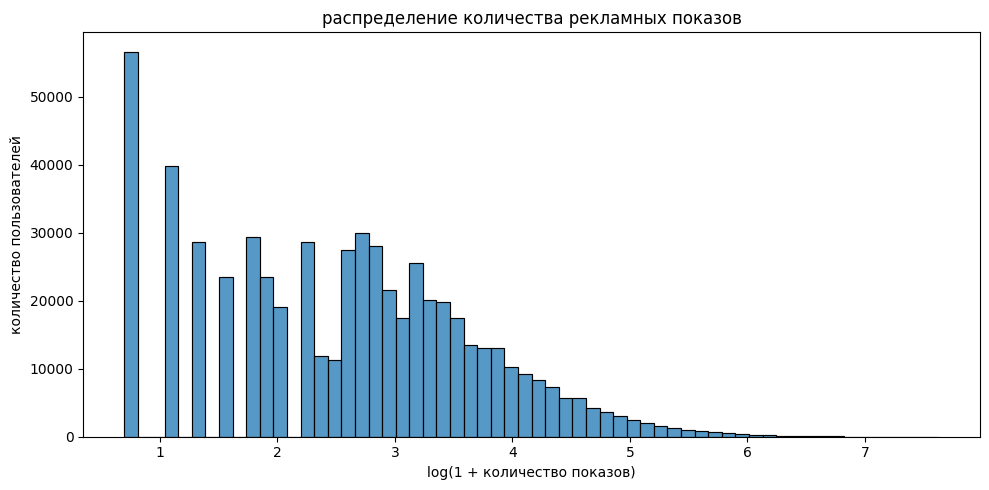

In [8]:
# распределение количества показов (логарифмическая шкала)
plt.figure(figsize=(10, 5))

sns.histplot(
    np.log1p(df['total ads']),
    bins=60
)

plt.title('распределение количества рекламных показов')
plt.xlabel('log(1 + количество показов)')
plt.ylabel('количество пользователей')

plt.tight_layout()
plt.show()

In [9]:
# сводка по предобработке
print('размер датасета:', df.shape)
print('пропущенных значений:', df.isna().sum().sum())
print('полных дубликатов:', df.duplicated().sum())
print('повторяющихся user_id:', df['user id'].duplicated().sum())
print(f"среднее число показов: {df['total ads'].mean():.2f}")
print(f"медиана числа показов: {df['total ads'].median():.0f}")
print(f"99-й процентиль: {df['total ads'].quantile(0.99):.0f}")
print(f'IQR-выбросов: {outliers_count} ({outliers_count / len(df) * 100:.2f}%), граница {upper_bound:.0f}')

размер датасета: (588101, 6)
пропущенных значений: 0
полных дубликатов: 0
повторяющихся user_id: 0
среднее число показов: 24.82
медиана числа показов: 13
99-й процентиль: 202
IQR-выбросов: 52057 (8.85%), граница 62


### выводы по предварительной обработке данных
В ходе анализа установлено:
- пропущенные значения и дубликаты отсутствуют, проверено явно (`isna`, `duplicated`, `assert`)
- каждому пользователю соответствует одна запись
- `converted` принимает только значения 0 и 1, в `test group` ровно две группы
- значения дней недели представлены семью корректными категориями, часы целые и лежат в диапазоне от 0 до 23
- распределение `total ads` имеет выраженную правостороннюю асимметрию и длинный правый хвост, поэтому для описания типичного значения используется медиана, а не среднее. Точные числа указаны в сводке выше

Потенциальные выбросы сохранены. Правило IQR на данных с длинным правым хвостом помечает значимую долю наблюдений, и это не обязательно ошибки: они могут отражать реальную интенсивность рекламного воздействия. Удаление без обоснования может сместить результаты эксперимента

Признаки total ads, most ads day и most ads hour характеризуют показы в ходе эксперимента и не используются для проверки исходной сопоставимости групп или корректировки оценки эффекта

## анализ экспериментальных групп
Проверим распределение пользователей между тестовой (`ad`) и контрольной (`psa`) группами и оценим ограничения, связанные с неравномерным распределением

In [10]:
# размеры групп
group_counts = df['test group'].value_counts()
group_percents = df['test group'].value_counts(normalize=True) * 100

group_summary = pd.DataFrame({
    'количество пользователей': group_counts,
    'доля пользователей, %': group_percents
})
display(group_summary.round(2))

n_ad = group_counts['ad']
n_psa = group_counts['psa']
print(f'соотношение групп ad : psa = {n_ad / n_psa:.1f} : 1')

,количество пользователей,"доля пользователей, %"
test group,,
ad,564577,96.0
psa,23524,4.0


соотношение групп ad : psa = 24.0 : 1


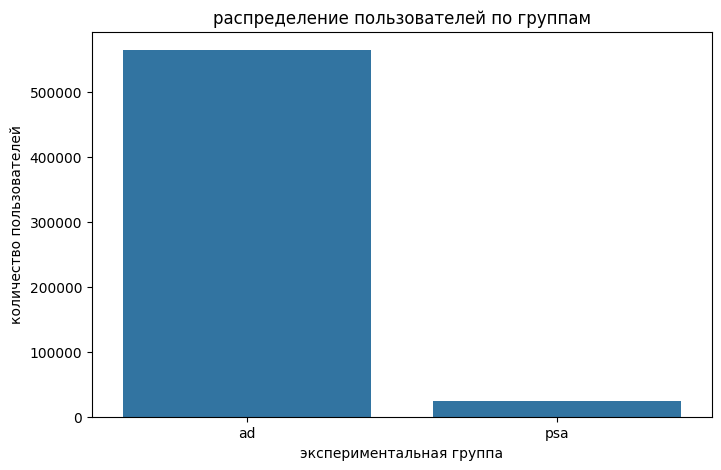

In [11]:
# визуализируем распределение
plt.figure(figsize=(8, 5))
sns.barplot(
    x=group_summary.index,
    y=group_summary['количество пользователей']
)
plt.title('распределение пользователей по группам')
plt.xlabel('экспериментальная группа')
plt.ylabel('количество пользователей')
plt.show()

### ограничения, связанные с распределением по группам
- группы неравны по размеру. Запланированное соотношение в описании датасета не указано, поэтому строгую проверку SRM провести нельзя
- существенно меньший размер группы psa ограничивает точность оценки разницы конверсий и статистическую мощность теста
- в данных нет признаков, известных до эксперимента, поэтому проверить баланс исходных характеристик нельзя. Сравнение характеристик показов ниже носит только описательный характер и не подтверждает корректность рандомизации

In [12]:
# описательное сравнение показов по группам
group_ads = df.groupby('test group')['total ads'].agg(
    ['median', 'mean', lambda x: x.quantile(0.95)]
)
group_ads.columns = ['медиана', 'среднее', '95-й процентиль']
display(group_ads.round(2))

for col in ['most ads day', 'most ads hour']:
    table = pd.crosstab(df[col], df['test group'], normalize='columns') * 100
    print(f'распределение {col} по группам, %:')
    display(table.round(2))

,медиана,среднее,95-й процентиль
test group,,,
ad,13.0,24.82,87.00
psa,12.0,24.76,92.85


распределение most ads day по группам, %:


test group,ad,psa
most ads day,,
Monday,14.80,14.89
Tuesday,13.21,12.36
Wednesday,13.71,14.84
Thursday,14.01,16.60
Friday,15.73,16.17
Saturday,13.96,12.15
Sunday,14.58,13.00


распределение most ads hour по группам, %:


test group,ad,psa
most ads hour,,
0,0.94,0.96
1,0.82,0.79
2,0.91,0.77
3,0.46,0.38
4,0.12,0.12
5,0.13,0.10
6,0.35,0.35
7,1.09,1.01
8,3.01,2.80


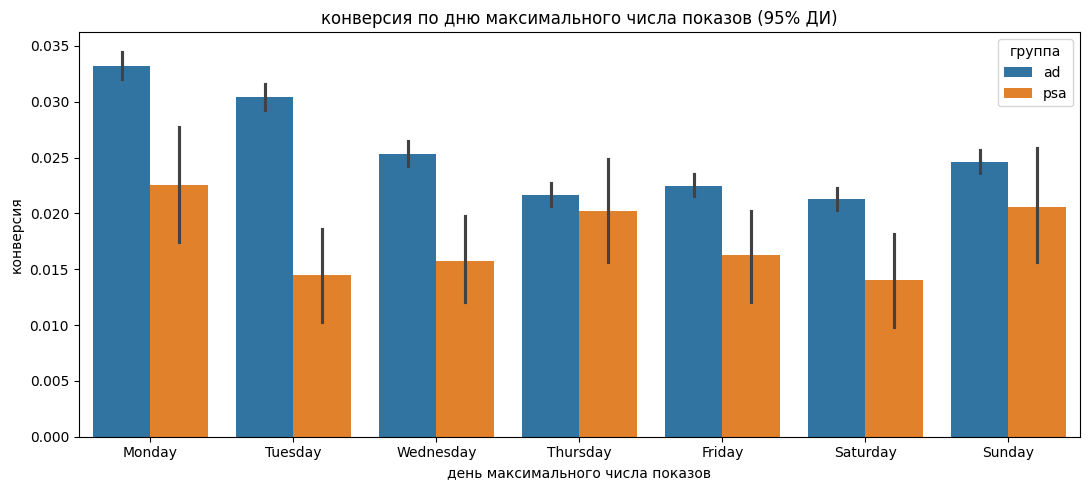

In [13]:
# конверсия по дню максимального числа показов

days_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

plt.figure(figsize=(11, 5))

sns.barplot(
    data=df,
    x='most ads day',
    y='converted',
    hue='test group',
    order=days_order,
    errorbar=('ci', 95),
    seed=42
)

plt.title('конверсия по дню максимального числа показов (95% ДИ)')
plt.xlabel('день максимального числа показов')
plt.ylabel('конверсия')
plt.legend(title='группа')
plt.tight_layout()
plt.show()

In [14]:
# таблица конверсий по дню максимального числа показов
# интервалы Уилсона учитывают неопределённость конверсии в каждой подгруппе
from statsmodels.stats.proportion import proportion_confint

day_summary = (
    df.groupby(['most ads day', 'test group'], observed=True)['converted']
    .agg(['count', 'sum'])
    .reset_index()
)

low, high = proportion_confint(
    day_summary['sum'],
    day_summary['count'],
    alpha=0.05,
    method='wilson'
)

day_summary['конверсия, %'] = day_summary['sum'] / day_summary['count'] * 100
day_summary['95% ДИ, %'] = [
    f'[{a * 100:.2f}; {b * 100:.2f}]' for a, b in zip(low, high)
]
day_summary = day_summary.rename(columns={'count': 'пользователей', 'sum': 'покупателей'})
display(day_summary.round(2))

,most ads day,test group,пользователей,покупателей,"конверсия, %","95% ДИ, %"
0,Monday,ad,83571,2778,3.32,[3.20; 3.45]
1,Monday,psa,3502,79,2.26,[1.81; 2.80]
2,Tuesday,ad,74572,2270,3.04,[2.92; 3.17]
3,Tuesday,psa,2907,42,1.44,[1.07; 1.95]
4,Wednesday,ad,77418,1963,2.54,[2.43; 2.65]
5,Wednesday,psa,3490,55,1.58,[1.21; 2.05]
6,Thursday,ad,79077,1711,2.16,[2.06; 2.27]
7,Thursday,psa,3905,79,2.02,[1.63; 2.51]
8,Friday,ad,88805,1995,2.25,[2.15; 2.35]
9,Friday,psa,3803,62,1.63,[1.27; 2.08]


`most ads day` - день, когда пользователю показывали больше всего объявлений, а не день покупки
поэтому график и таблицы выше показывают описательную связь между этой категорией и конверсией
различия между днями нельзя интерпретировать как эффект выбора дня показа: категория определяется в ходе эксперимента. Сравнивать только высоту столбцов без численности подгрупп и доверительных интервалов некорректно

в датасете converted отражает только факт покупки, времени покупки и времени отдельных показов нет, поэтому установить, когда произошла конверсия относительно показов, невозможно

столбцы показывают долю покупателей среди пользователей с соответствующим днём максимального числа показов, чёрные линии - 95% bootstrap-ди конверсий, рассчитанные seaborn, в таблице выше для отдельных конверсий использованы 95% ди уилсона, поэтому их границы могут немного отличаться

выводы по описательному сравнению групп:
в эксперименте участвовали 564 577 пользователей группы ad и 23 524 группы psa, распределение составило примерно 96% и 4%, однако без информации о плановых долях проверить наличие SRM невозможно
интенсивность показов в группах практически не отличается: среднее количество показов составляет 24,82 в ad и 24,76 в psa, медианы - 13 и 12 соответственно
на уровне 95-го процентиля наблюдается различие: 87 показов в ad против 92,85 в psa, однако без статистической проверки нельзя утверждать, что оно значимо
распределение по most ads day различается: в ad наибольшая доля пользователей приходится на пятницу (15,73%), в psa - на четверг (16,60%), при этом наиболее распространённый час показов совпадает - 13:00 (8,06% и 9,22% соответственно)
ограничения интерпретации:
total ads, most ads day и most ads hour характеризуют показы пользователям в ходе эксперимента и не являются исходными характеристиками пользователей
различия по дням и часам носят описательный характер и не позволяют определить наиболее эффективное время размещения рекламы
сравнение конверсий по most ads day не отражает влияние конкретного дня на вероятность покупки, поскольку показатель фиксирует день максимального числа показов, а не день конверсии

## расчёт конверсий по группам


In [15]:
# расчёт конверсии по экспериментальным группам
conversion_summary = df.groupby('test group').agg(
    users=('user id', 'nunique'),
    conversions=('converted', 'sum'),
    conversion_rate=('converted', 'mean')
)

# перевод конверсии в проценты
conversion_summary['conversion_rate'] *= 100

display(conversion_summary.round(3))

,users,conversions,conversion_rate
test group,,,
ad,564577,14423,2.555
psa,23524,420,1.785


## чувствительность теста (mde)
ретроспективно оценила минимальный положительный эффект, который тест мог бы обнаруживать с мощностью 80% при α = 0,05, фактических размерах групп и наблюдаемой конверсии контроля
полученное значение mde характеризует чувствительность теста в рамках принятых предпосылок и не является жёстким порогом обнаружения эффекта, заранее установленным параметром эксперимента или критерием экономической целесообразности рекламы

In [16]:
# расчёт MDE по фактическим размерам групп
p_psa = df.loc[df['test group'] == 'psa', 'converted'].mean()

analysis = NormalIndPower()
h = analysis.solve_power(
    effect_size=None,
    nobs1=n_psa,
    alpha=0.05,
    power=0.8,
    ratio=n_ad / n_psa,
    alternative='two-sided'
)

# переводим эффект h Коэна обратно в конверсию
p_detectable = np.sin(np.arcsin(np.sqrt(p_psa)) + h / 2) ** 2

print(f'конверсия в контрольной группе: {p_psa * 100:.3f}%')
print(f'минимально обнаруживаемая конверсия в группе ad: {p_detectable * 100:.3f}%')
print(f'MDE: {(p_detectable - p_psa) * 100:.3f} п.п. (относительно {(p_detectable / p_psa - 1) * 100:.1f}%)')

конверсия в контрольной группе: 1.785%
минимально обнаруживаемая конверсия в группе ad: 2.041%
MDE: 0.255 п.п. (относительно 14.3%)


проверка основной гипотезы: z-тест двух пропорций
основная гипотеза сформулирована для всей выборки: H₀ - конверсии ad и psa одинаковы; H₁ - различаются. Уровень значимости - 0,05; тест двусторонний
основной показатель для продуктового вывода - разница конверсий с 95%-м доверительным интервалом Ньюкомба
относительный uplift сопровождается отдельным доверительным интервалом по логарифмическому дельта-методу (отношение рисков)

In [17]:
# z-тест для сравнения конверсий двух групп
# количество пользователей и конверсий
ad = df[df['test group'] == 'ad']
psa = df[df['test group'] == 'psa']

n_ad = len(ad)
n_psa = len(psa)

conv_ad = ad['converted'].sum()
conv_psa = psa['converted'].sum()

# конверсии групп
p_ad = conv_ad / n_ad
p_psa = conv_psa / n_psa

# проверка гипотезы
z_stat, p_value = proportions_ztest(
    count=[conv_ad, conv_psa],
    nobs=[n_ad, n_psa],
    alternative='two-sided'
)

# 95%-й доверительный интервал разницы конверсий
ci_low, ci_high = confint_proportions_2indep(
    count1=conv_ad,
    nobs1=n_ad,
    count2=conv_psa,
    nobs2=n_psa,
    compare='diff',
    method='newcomb',
    alpha=0.05
)

# абсолютный и относительный прирост конверсии
absolute_uplift = (p_ad - p_psa) * 100
relative_uplift = (p_ad / p_psa - 1) * 100

print(f'конверсия ad: {p_ad * 100:.3f}%')
print(f'конверсия psa: {p_psa * 100:.3f}%')
print(f'абсолютный uplift: {absolute_uplift:.3f} п.п.')
print(f'относительный uplift: {relative_uplift:.2f}%')

print(f'\nz-статистика: {z_stat:.4f}')
print(f'p-value: {p_value:.6g}')
print(f'95%-й ди: [{ci_low * 100:.3f}; {ci_high * 100:.3f}] п.п.')

if p_value < 0.05:
    print('\nнулевая гипотеза отвергается')
else:
    print('\nнет оснований отвергнуть нулевую гипотезу')


rr_low, rr_high = confint_proportions_2indep(
    count1=conv_ad,
    nobs1=n_ad,
    count2=conv_psa,
    nobs2=n_psa,
    compare="ratio",
    method="log",
    alpha=0.05
)

print(
    f"95% ДИ относительного uplift: "
    f"[{(rr_low - 1) * 100:.2f}%; "
    f"{(rr_high - 1) * 100:.2f}%]"
)


конверсия ad: 2.555%
конверсия psa: 1.785%
абсолютный uplift: 0.769 п.п.
относительный uplift: 43.09%

z-статистика: 7.3701
p-value: 1.70528e-13
95%-й ди: [0.587; 0.936] п.п.

нулевая гипотеза отвергается
95% ДИ относительного uplift: [29.97%; 57.52%]


## выводы по a/b-тесту
- конверсия в группе `ad` - 2,555%, в `psa` - 1,785%. Разница составляет около 0,769 п.п. (95% ДИ: [0,587; 0,936] п.п.), относительный uplift - 43,09%. Двусторонний z-тест: p < 0,001
- нулевая гипотеза о равенстве конверсий отвергается на уровне значимости 0,05. При выполнении предпосылок рандомизированного эксперимента результат совместим с положительным эффектом рекламного воздействия на конверсию
- проверить корректность рандомизации и SRM по этим данным нельзя: неизвестна запланированная доля групп, нет характеристик пользователей до эксперимента. Информация о днях, часах и числе показов собрана в ходе эксперимента и не позволяет выбрать лучшее время для рекламы
- converted показывает факт покупки, но в датасете нет времени покупок и отдельных показов, поэтому по этим данным нельзя проверить последовательность событий или оценить эффективность конкретного дня показа
- для решения о масштабировании рекламы не хватает стоимости показов, маржи/ценности покупки и guardrail-метрик. Я бы рекомендовала сначала подтвердить корректность распределения пользователей и оценить прибыль от дополнительных конверсий. Статистическая значимость сама по себе не означает экономическую выгоду